In [87]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import IsolationForest

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

In [88]:
df = pd.read_csv("ec2_cpu_utilization_5f5533.csv")

print("Dataset Shape:", df.shape)
print("\nColumns:", df.columns.tolist())

display(df.head())

Dataset Shape: (4032, 2)

Columns: ['timestamp', 'value']


,timestamp,value
0,2014-02-14 14:27:00,51.8460
1,2014-02-14 14:32:00,44.5080
2,2014-02-14 14:37:00,41.2440
3,2014-02-14 14:42:00,48.5680
4,2014-02-14 14:47:00,46.7140


In [89]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nDuplicate Timestamps:", df["timestamp"].duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4032 entries, 0 to 4031
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   timestamp  4032 non-null   object 
 1   value      4032 non-null   float64
dtypes: float64(1), object(1)
memory usage: 63.1+ KB

Missing Values:
timestamp    0
value        0
dtype: int64

Duplicate Rows: 0

Duplicate Timestamps: 0


In [90]:
df["timestamp"] = pd.to_datetime(df["timestamp"])

df = df.sort_values("timestamp").reset_index(drop=True)

print("First Timestamp:", df["timestamp"].min())
print("Last Timestamp:", df["timestamp"].max())

display(df.head())

First Timestamp: 2014-02-14 14:27:00
Last Timestamp: 2014-02-28 14:22:00


,timestamp,value
0,2014-02-14 14:27:00,51.8460
1,2014-02-14 14:32:00,44.5080
2,2014-02-14 14:37:00,41.2440
3,2014-02-14 14:42:00,48.5680
4,2014-02-14 14:47:00,46.7140


In [91]:
time_difference = df["timestamp"].diff().dropna()

print("Time Interval Counts:")
print(time_difference.value_counts().head(10))

print("\nMinimum Interval:", time_difference.min())
print("Maximum Interval:", time_difference.max())

Time Interval Counts:
timestamp
0 days 00:05:00    4031
Name: count, dtype: int64

Minimum Interval: 0 days 00:05:00
Maximum Interval: 0 days 00:05:00


In [92]:
display(df.describe())

print("Mean CPU Utilization:", df["value"].mean())
print("Standard Deviation:", df["value"].std())
print("Minimum CPU Utilization:", df["value"].min())
print("Maximum CPU Utilization:", df["value"].max())

,timestamp,value
count,4032,4032.0000
mean,2014-02-21 14:24:30,43.1104
min,2014-02-14 14:27:00,34.7660
25%,2014-02-18 02:25:45,39.2960
50%,2014-02-21 14:24:30,42.9180
75%,2014-02-25 02:23:15,46.0060
max,2014-02-28 14:22:00,68.0920
std,NaN,4.3036


Mean CPU Utilization: 43.11037160218254
Standard Deviation: 4.303564641024769
Minimum CPU Utilization: 34.766
Maximum CPU Utilization: 68.092


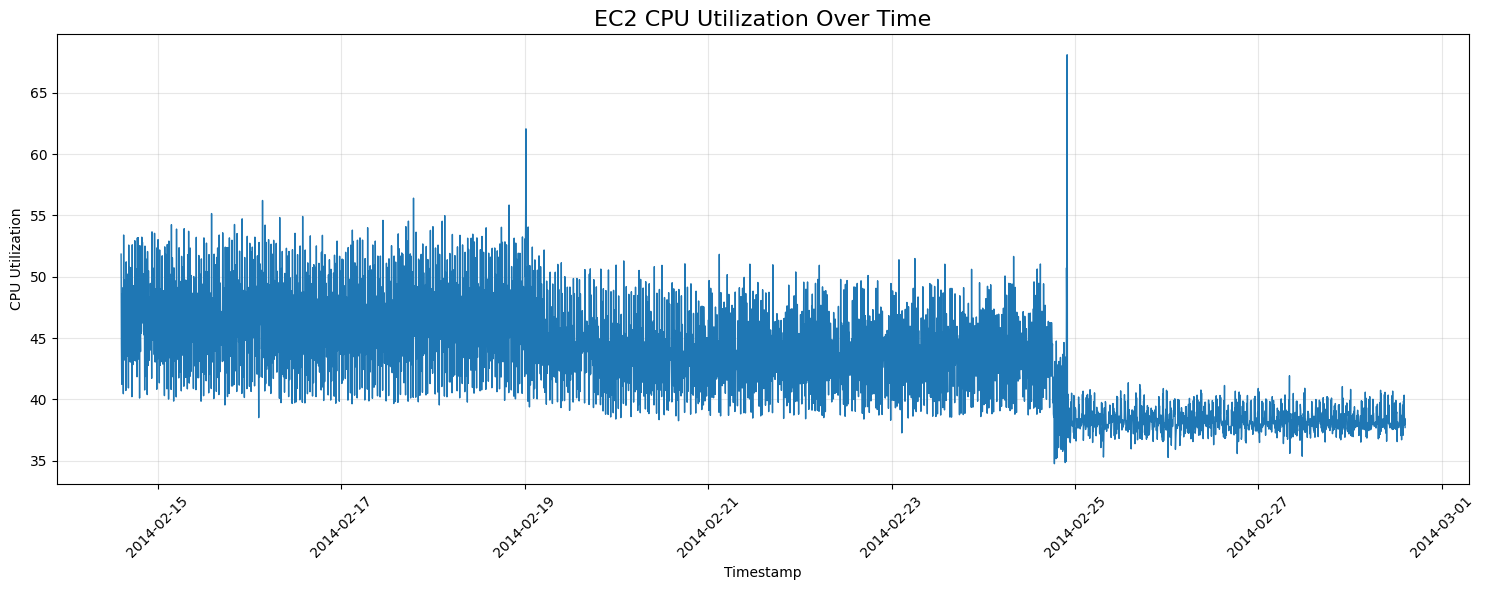

In [93]:
plt.figure(figsize=(15, 6))

plt.plot(
    df["timestamp"],
    df["value"],
    linewidth=1
)

plt.title("EC2 CPU Utilization Over Time", fontsize=16)
plt.xlabel("Timestamp")
plt.ylabel("CPU Utilization")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

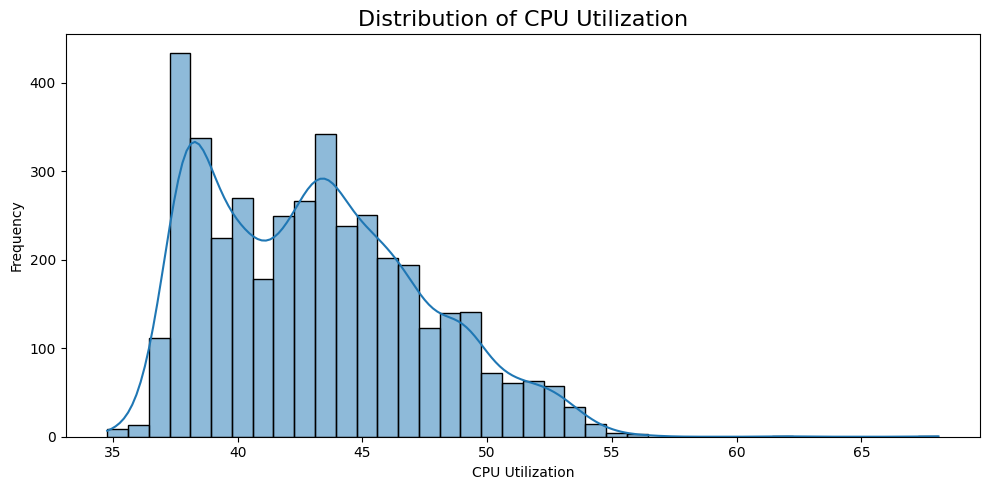

In [94]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["value"],
    kde=True,
    bins=40
)

plt.title("Distribution of CPU Utilization", fontsize=16)
plt.xlabel("CPU Utilization")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

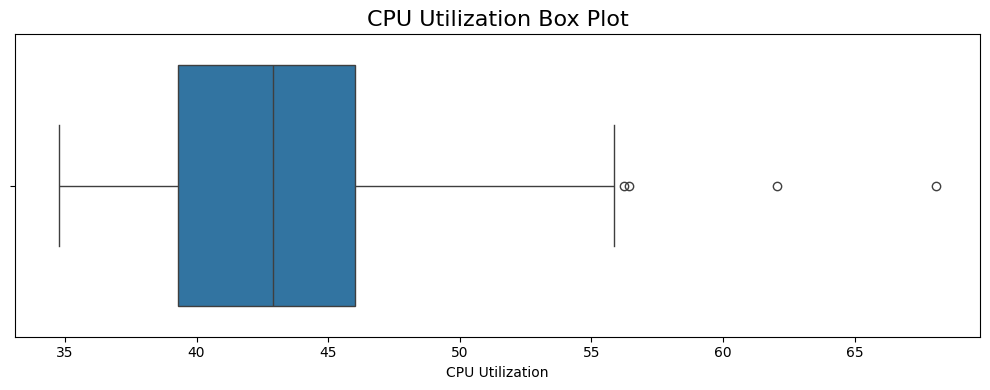

In [95]:
plt.figure(figsize=(10, 4))

sns.boxplot(
    x=df["value"]
)

plt.title("CPU Utilization Box Plot", fontsize=16)
plt.xlabel("CPU Utilization")

plt.tight_layout()
plt.show()

In [96]:
data = df.copy()

data["hour"] = data["timestamp"].dt.hour
data["day_of_week"] = data["timestamp"].dt.dayofweek
data["day"] = data["timestamp"].dt.day

data["lag_1"] = data["value"].shift(1)
data["lag_2"] = data["value"].shift(2)
data["lag_3"] = data["value"].shift(3)
data["lag_6"] = data["value"].shift(6)
data["lag_12"] = data["value"].shift(12)
data["lag_24"] = data["value"].shift(24)

data["rolling_mean_12"] = (
    data["value"]
    .shift(1)
    .rolling(12)
    .mean()
)

data["rolling_std_12"] = (
    data["value"]
    .shift(1)
    .rolling(12)
    .std()
)

data["rolling_mean_24"] = (
    data["value"]
    .shift(1)
    .rolling(24)
    .mean()
)

data["rolling_std_24"] = (
    data["value"]
    .shift(1)
    .rolling(24)
    .std()
)

data = data.dropna().reset_index(drop=True)

display(data.head())

,timestamp,value,hour,day_of_week,day,lag_1,lag_2,lag_3,lag_6,lag_12,lag_24,rolling_mean_12,rolling_std_12,rolling_mean_24,rolling_std_24
0,2014-02-14 16:27:00,52.5860,16,4,14,40.9420,48.8500,43.5440,45.0000,46.3700,51.8460,46.0527,3.3792,46.3257,3.6550
1,2014-02-14 16:32:00,45.8020,16,4,14,52.5860,40.9420,48.8500,50.2240,43.7560,44.5080,46.5707,3.8727,46.3565,3.7064
2,2014-02-14 16:37:00,43.1220,16,4,14,45.8020,52.5860,40.9420,48.0960,47.5820,41.2440,46.7412,3.7814,46.4104,3.6877
3,2014-02-14 16:42:00,50.7740,16,4,14,43.1220,45.8020,52.5860,43.5440,40.7380,48.5680,46.3695,3.9083,46.4887,3.5920
4,2014-02-14 16:47:00,46.2620,16,4,14,50.7740,43.1220,45.8020,48.8500,51.2160,46.7140,47.2058,3.6596,46.5806,3.6748


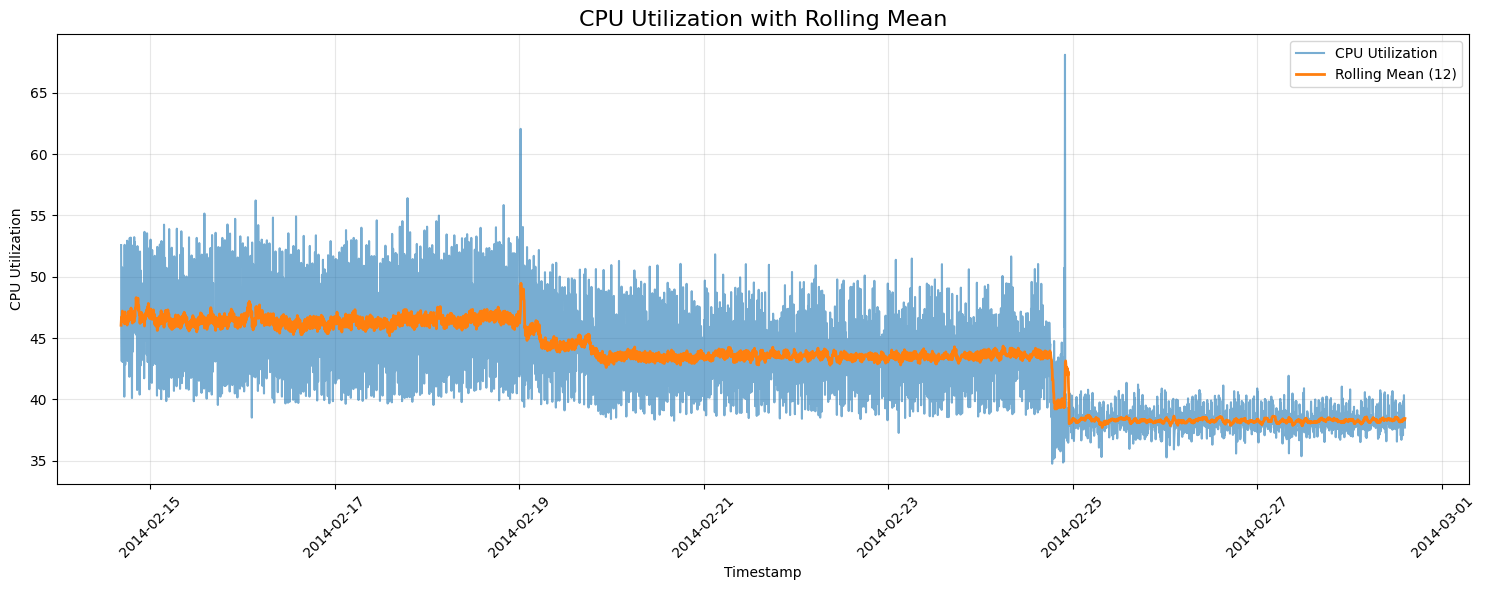

In [97]:
plt.figure(figsize=(15, 6))

plt.plot(
    data["timestamp"],
    data["value"],
    label="CPU Utilization",
    alpha=0.6
)

plt.plot(
    data["timestamp"],
    data["rolling_mean_12"],
    label="Rolling Mean (12)",
    linewidth=2
)

plt.title("CPU Utilization with Rolling Mean", fontsize=16)
plt.xlabel("Timestamp")
plt.ylabel("CPU Utilization")

plt.legend()
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

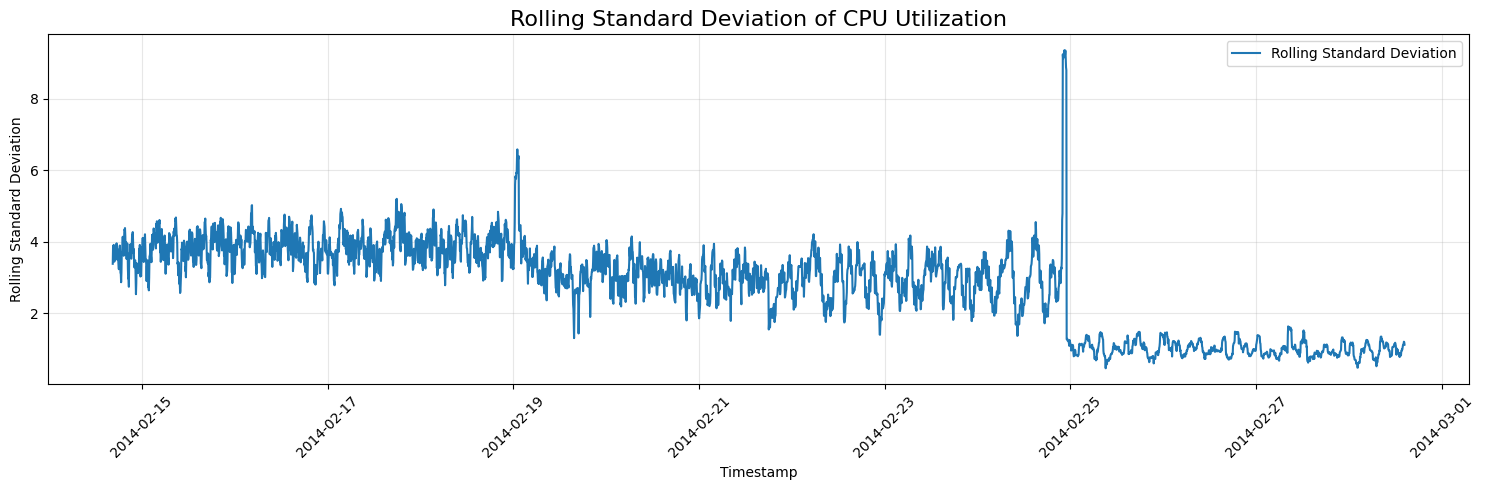

In [98]:
plt.figure(figsize=(15, 5))

plt.plot(
    data["timestamp"],
    data["rolling_std_12"],
    label="Rolling Standard Deviation"
)

plt.title("Rolling Standard Deviation of CPU Utilization", fontsize=16)
plt.xlabel("Timestamp")
plt.ylabel("Rolling Standard Deviation")

plt.legend()
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [99]:
mean_value = data["value"].mean()
std_value = data["value"].std()

data["z_score"] = (
    (data["value"] - mean_value) /
    std_value
)

z_threshold = 3

data["z_anomaly"] = (
    data["z_score"].abs() > z_threshold
).astype(int)

print("Z-Score Threshold:", z_threshold)
print("Z-Score Anomalies:", data["z_anomaly"].sum())

print(
    "Z-Score Anomaly Percentage:",
    round(data["z_anomaly"].mean() * 100, 2),
    "%"
)

Z-Score Threshold: 3
Z-Score Anomalies: 4
Z-Score Anomaly Percentage: 0.1 %


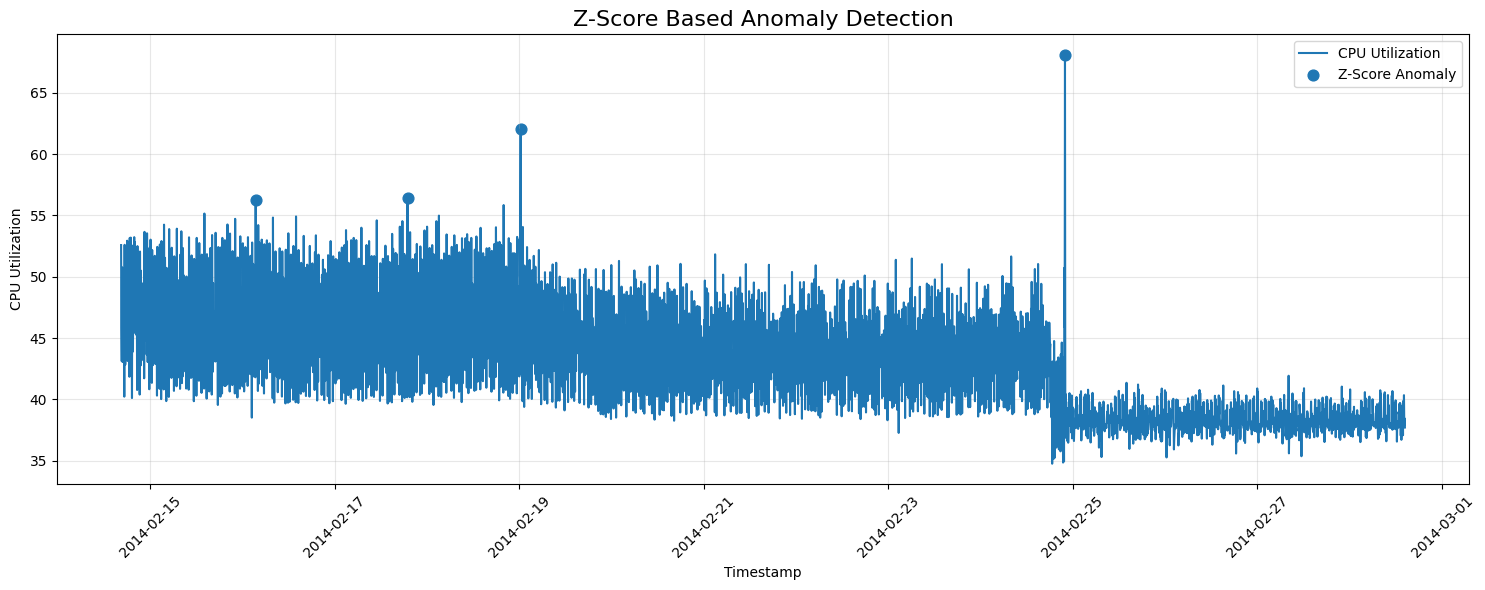

In [100]:
plt.figure(figsize=(15, 6))

plt.plot(
    data["timestamp"],
    data["value"],
    label="CPU Utilization"
)

z_anomalies = data[
    data["z_anomaly"] == 1
]

plt.scatter(
    z_anomalies["timestamp"],
    z_anomalies["value"],
    label="Z-Score Anomaly",
    s=60
)

plt.title("Z-Score Based Anomaly Detection", fontsize=16)
plt.xlabel("Timestamp")
plt.ylabel("CPU Utilization")

plt.legend()
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [101]:
train_size = int(len(data) * 0.80)

train_data = data.iloc[:train_size].copy()
test_data = data.iloc[train_size:].copy()

print("Total Records:", len(data))
print("Training Records:", len(train_data))
print("Testing Records:", len(test_data))

print("\nTraining Period:")
print(
    train_data["timestamp"].min(),
    "to",
    train_data["timestamp"].max()
)

print("\nTesting Period:")
print(
    test_data["timestamp"].min(),
    "to",
    test_data["timestamp"].max()
)

Total Records: 4008
Training Records: 3206
Testing Records: 802

Training Period:
2014-02-14 16:27:00 to 2014-02-25 19:32:00

Testing Period:
2014-02-25 19:37:00 to 2014-02-28 14:22:00


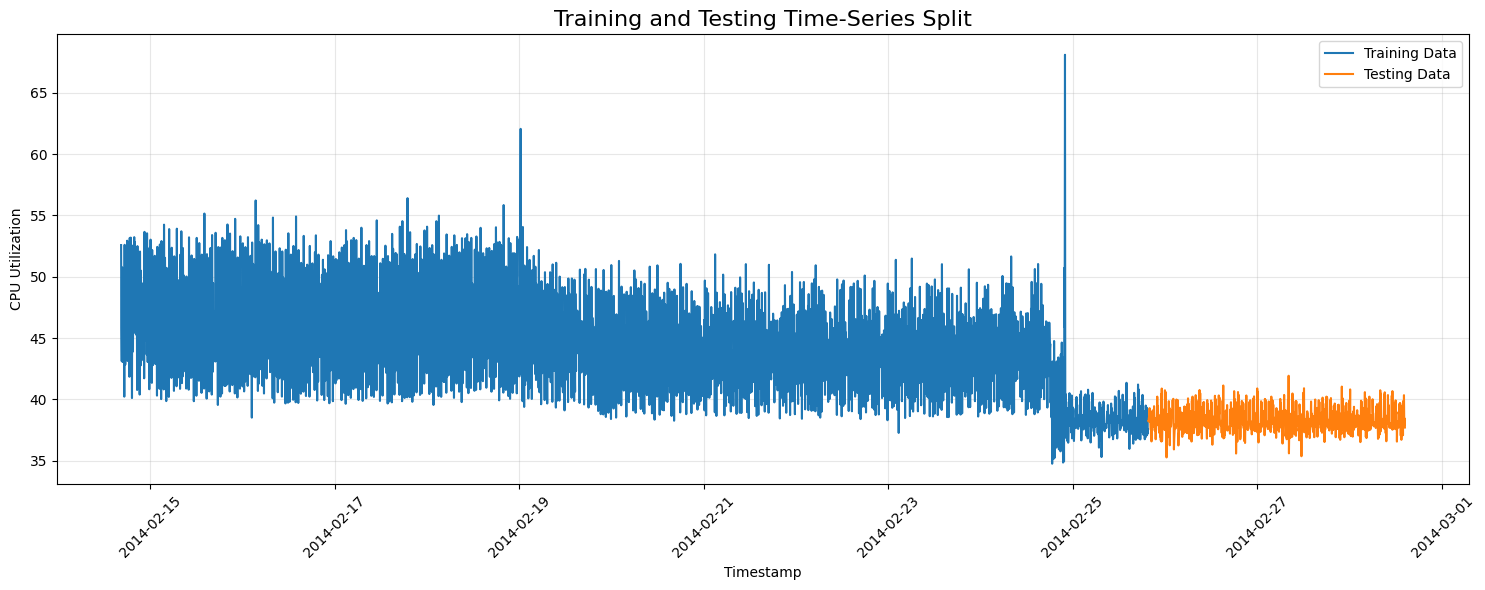

In [102]:
plt.figure(figsize=(15, 6))

plt.plot(
    train_data["timestamp"],
    train_data["value"],
    label="Training Data"
)

plt.plot(
    test_data["timestamp"],
    test_data["value"],
    label="Testing Data"
)

plt.title("Training and Testing Time-Series Split", fontsize=16)
plt.xlabel("Timestamp")
plt.ylabel("CPU Utilization")

plt.legend()
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [103]:
features = [
    "value",
    "hour",
    "day_of_week",
    "lag_1",
    "lag_2",
    "lag_3",
    "lag_6",
    "lag_12",
    "lag_24",
    "rolling_mean_12",
    "rolling_std_12",
    "rolling_mean_24",
    "rolling_std_24"
]

X_train = train_data[features]
X_test = test_data[features]

print("Number of Features:", len(features))

print("\nFeatures:")
print(features)

print("\nTraining Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

Number of Features: 13

Features:
['value', 'hour', 'day_of_week', 'lag_1', 'lag_2', 'lag_3', 'lag_6', 'lag_12', 'lag_24', 'rolling_mean_12', 'rolling_std_12', 'rolling_mean_24', 'rolling_std_24']

Training Shape: (3206, 13)
Testing Shape: (802, 13)


In [104]:
contamination_value = 0.02

model = IsolationForest(
    n_estimators=200,
    contamination=contamination_value,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train)

print("Isolation Forest Model Trained")
print("Contamination:", contamination_value)

Isolation Forest Model Trained
Contamination: 0.02


In [105]:
test_data["prediction"] = model.predict(X_test)

test_data["anomaly"] = (
    test_data["prediction"] == -1
).astype(int)

test_data["anomaly_score"] = (
    model.decision_function(X_test)
)

print("Prediction Completed")

print("\nPrediction Counts:")
print(test_data["prediction"].value_counts())

Prediction Completed

Prediction Counts:
prediction
 1    716
-1     86
Name: count, dtype: int64


In [106]:
anomaly_count = test_data["anomaly"].sum()
normal_count = len(test_data) - anomaly_count

anomaly_percentage = (
    anomaly_count /
    len(test_data)
) * 100

print("Total Test Records:", len(test_data))
print("Normal Records:", normal_count)
print("Anomalous Records:", anomaly_count)

print(
    "Anomaly Percentage:",
    round(anomaly_percentage, 2),
    "%"
)

Total Test Records: 802
Normal Records: 716
Anomalous Records: 86
Anomaly Percentage: 10.72 %


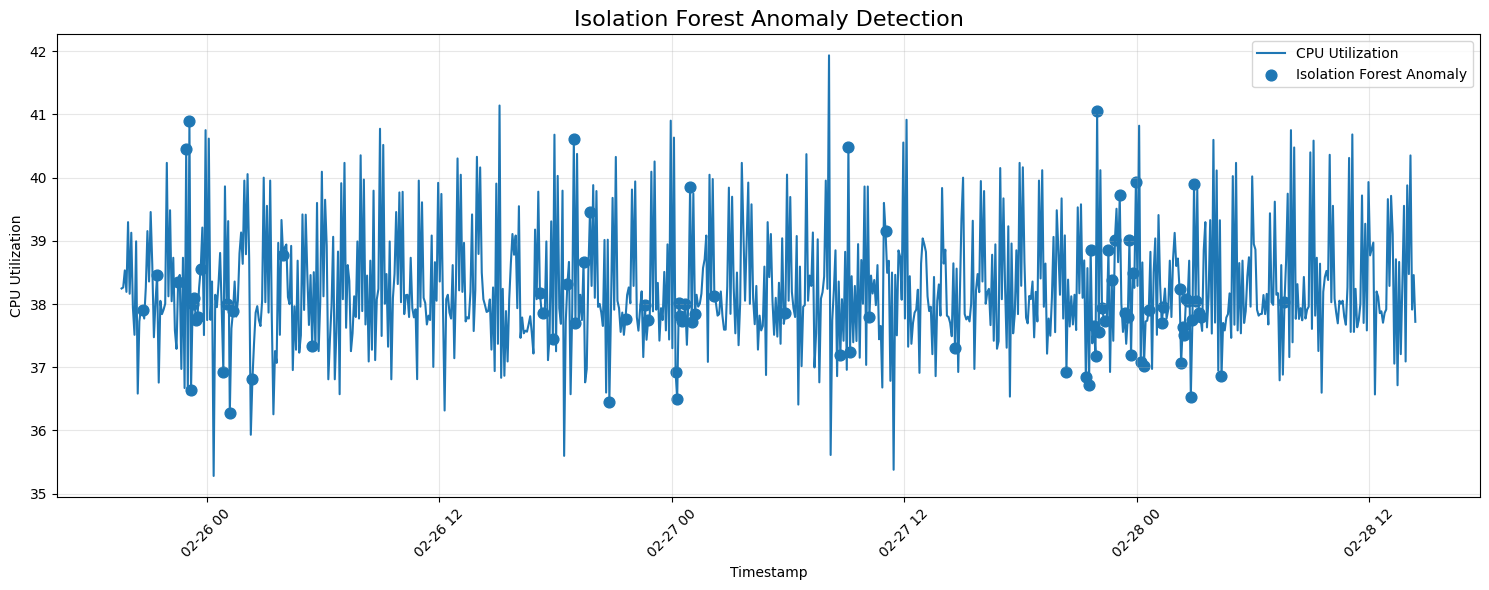

In [107]:
plt.figure(figsize=(15, 6))

plt.plot(
    test_data["timestamp"],
    test_data["value"],
    label="CPU Utilization"
)

iforest_anomalies = test_data[
    test_data["anomaly"] == 1
]

plt.scatter(
    iforest_anomalies["timestamp"],
    iforest_anomalies["value"],
    label="Isolation Forest Anomaly",
    s=60
)

plt.title("Isolation Forest Anomaly Detection", fontsize=16)
plt.xlabel("Timestamp")
plt.ylabel("CPU Utilization")

plt.legend()
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

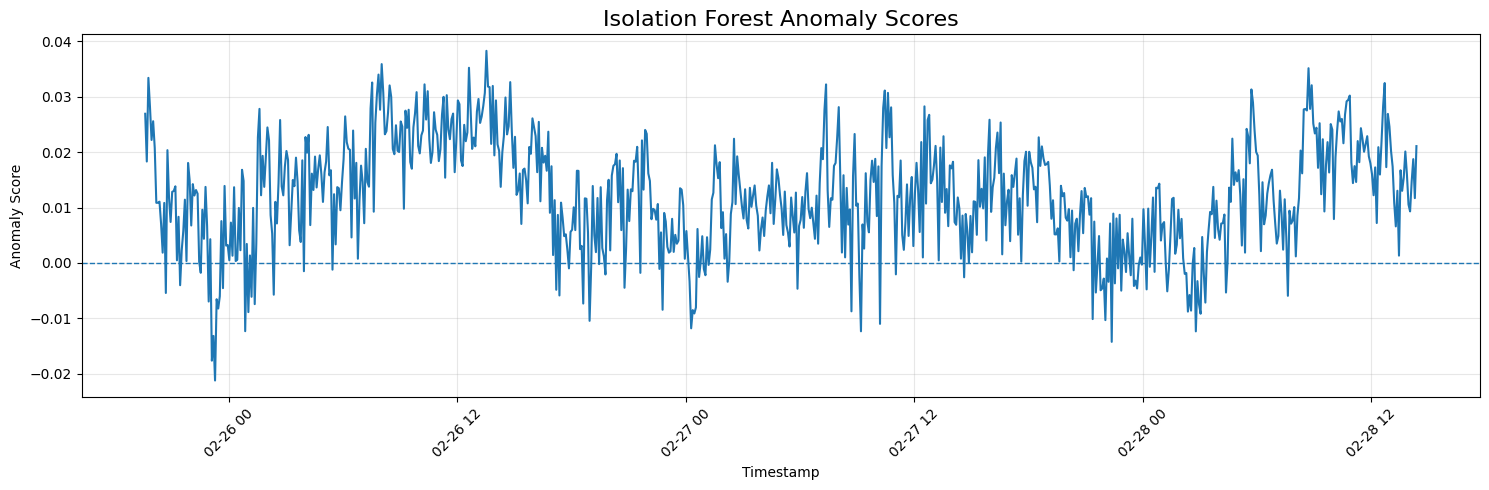

In [108]:
plt.figure(figsize=(15, 5))

plt.plot(
    test_data["timestamp"],
    test_data["anomaly_score"]
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

plt.title("Isolation Forest Anomaly Scores", fontsize=16)
plt.xlabel("Timestamp")
plt.ylabel("Anomaly Score")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [109]:
detected_anomalies = test_data[
    test_data["anomaly"] == 1
][
    [
        "timestamp",
        "value",
        "anomaly_score"
    ]
].sort_values(
    "anomaly_score"
)

print("Detected Anomalies:")
display(detected_anomalies)

Detected Anomalies:


,timestamp,value,anomaly_score
3250,2014-02-25 23:17:00,38.0040,-0.0212
3248,2014-02-25 23:07:00,40.8940,-0.0176
3815,2014-02-27 22:22:00,37.7240,-0.0142
3249,2014-02-25 23:12:00,36.6440,-0.0132
3868,2014-02-28 02:47:00,36.5260,-0.0123
...,...,...,...
3561,2014-02-27 01:12:00,37.8400,-0.0003
3834,2014-02-27 23:57:00,39.9340,-0.0003
3492,2014-02-26 19:27:00,38.6620,-0.0002
3866,2014-02-28 02:37:00,38.0400,-0.0002


In [110]:
z_test_count = test_data["z_anomaly"].sum()
iforest_test_count = test_data["anomaly"].sum()

comparison = pd.DataFrame({
    "Method": [
        "Z-Score",
        "Isolation Forest"
    ],
    "Anomalies Detected": [
        z_test_count,
        iforest_test_count
    ],
    "Percentage": [
        z_test_count / len(test_data) * 100,
        iforest_test_count / len(test_data) * 100
    ]
})

display(comparison)

,Method,Anomalies Detected,Percentage
0,Z-Score,0,0.0000
1,Isolation Forest,86,10.7232


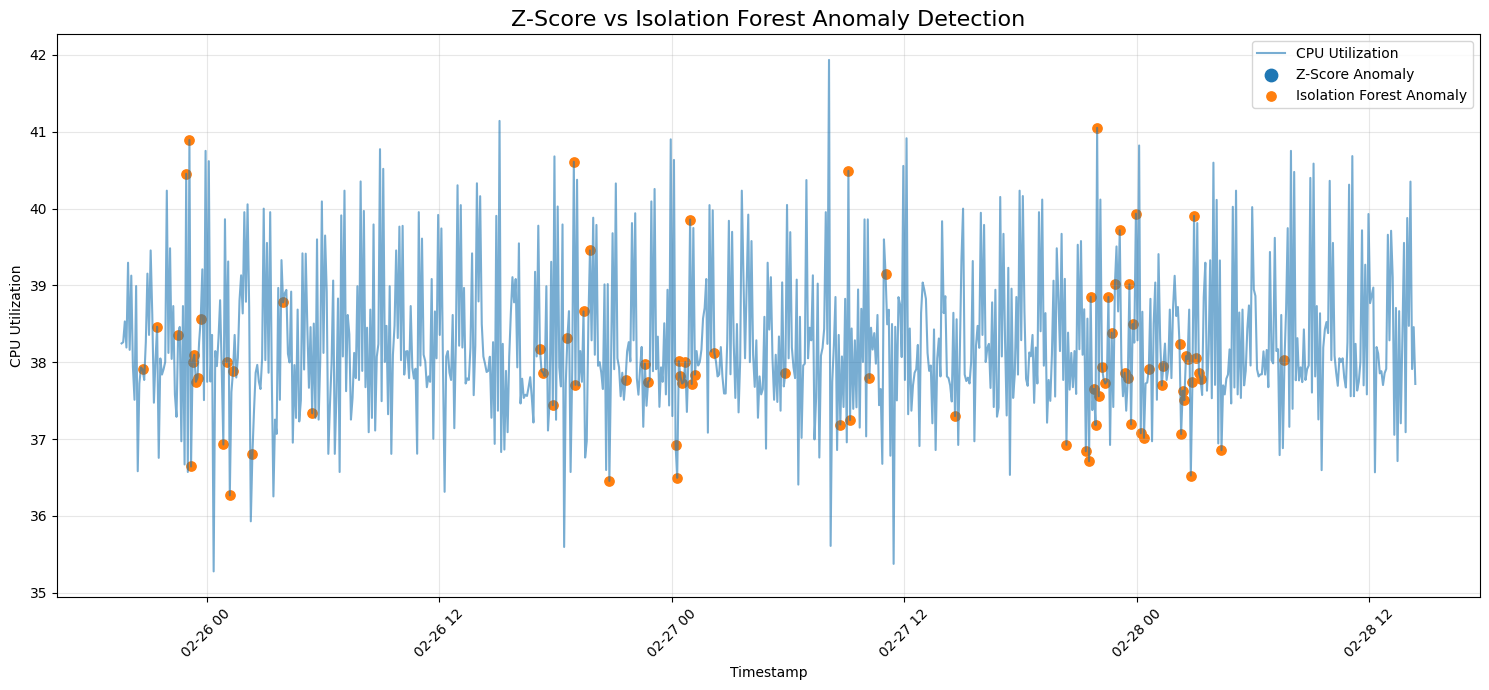

In [111]:
plt.figure(figsize=(15, 7))

plt.plot(
    test_data["timestamp"],
    test_data["value"],
    label="CPU Utilization",
    alpha=0.6
)

z_test_anomalies = test_data[
    test_data["z_anomaly"] == 1
]

iforest_test_anomalies = test_data[
    test_data["anomaly"] == 1
]

plt.scatter(
    z_test_anomalies["timestamp"],
    z_test_anomalies["value"],
    label="Z-Score Anomaly",
    s=80
)

plt.scatter(
    iforest_test_anomalies["timestamp"],
    iforest_test_anomalies["value"],
    label="Isolation Forest Anomaly",
    s=45
)

plt.title(
    "Z-Score vs Isolation Forest Anomaly Detection",
    fontsize=16
)

plt.xlabel("Timestamp")
plt.ylabel("CPU Utilization")

plt.legend()
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

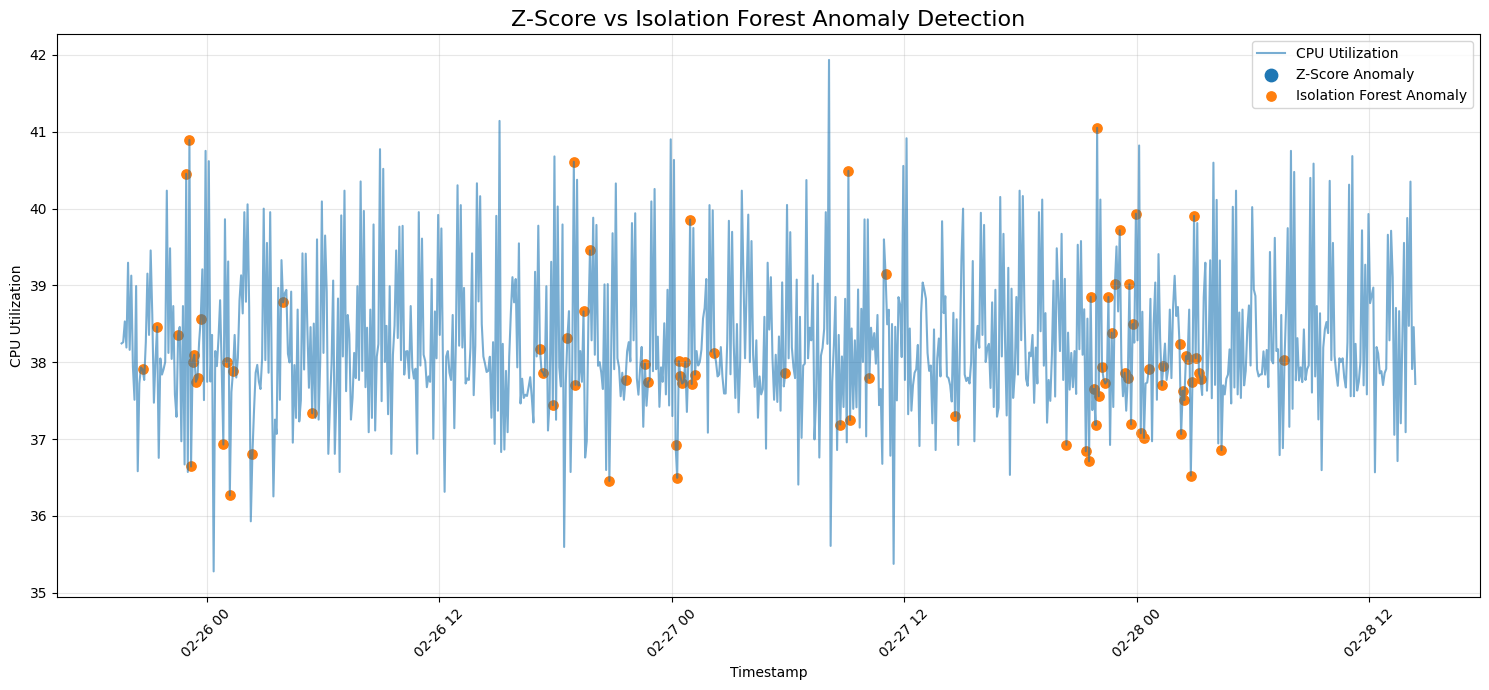

In [112]:
plt.figure(figsize=(15, 7))

plt.plot(
    test_data["timestamp"],
    test_data["value"],
    label="CPU Utilization",
    alpha=0.6
)

z_test_anomalies = test_data[
    test_data["z_anomaly"] == 1
]

iforest_test_anomalies = test_data[
    test_data["anomaly"] == 1
]

plt.scatter(
    z_test_anomalies["timestamp"],
    z_test_anomalies["value"],
    label="Z-Score Anomaly",
    s=80
)

plt.scatter(
    iforest_test_anomalies["timestamp"],
    iforest_test_anomalies["value"],
    label="Isolation Forest Anomaly",
    s=45
)

plt.title(
    "Z-Score vs Isolation Forest Anomaly Detection",
    fontsize=16
)

plt.xlabel("Timestamp")
plt.ylabel("CPU Utilization")

plt.legend()
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Contamination Sensitivity Analysis:


,Contamination,Detected Anomalies
0,0.0100,0
1,0.0200,86
2,0.0300,277
3,0.0400,474
4,0.0500,573
5,0.0600,653
6,0.0700,717
7,0.0800,762
8,0.0900,786
9,0.1000,800


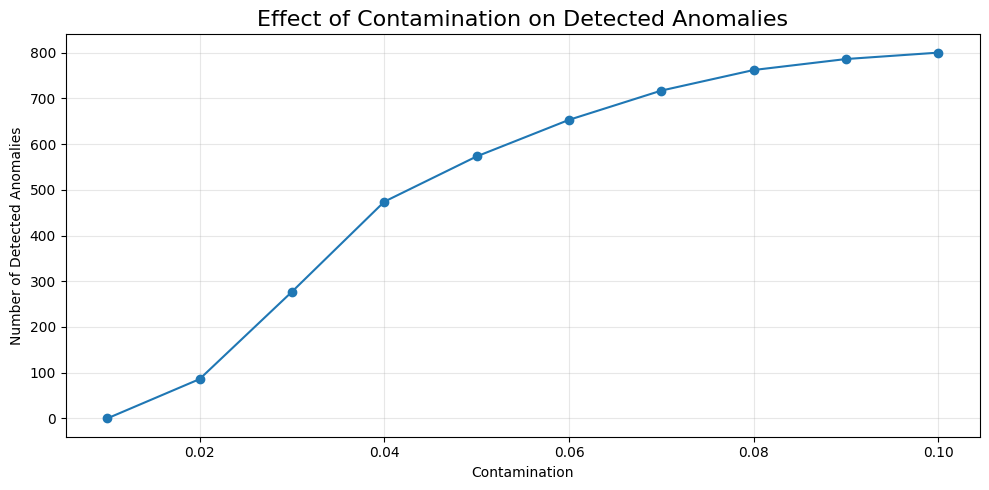

In [113]:
contamination_values = np.linspace(0.01, 0.1, 10)
anomalies_detected = []

for contam in contamination_values:
    model_sensitivity = IsolationForest(
        n_estimators=200,
        contamination=contam,
        random_state=42,
        n_jobs=-1
    )
    model_sensitivity.fit(X_train)
    test_predictions = model_sensitivity.predict(X_test)
    num_anomalies = (test_predictions == -1).sum()
    anomalies_detected.append(num_anomalies)

sensitivity_df = pd.DataFrame({
    "Contamination": contamination_values,
    "Detected Anomalies": anomalies_detected
})

print("Contamination Sensitivity Analysis:")
display(sensitivity_df)

plt.figure(figsize=(10, 5))

plt.plot(
    sensitivity_df["Contamination"],
    sensitivity_df["Detected Anomalies"],
    marker="o"
)

plt.title(
    "Effect of Contamination on Detected Anomalies",
    fontsize=16
)

plt.xlabel("Contamination")
plt.ylabel("Number of Detected Anomalies")

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

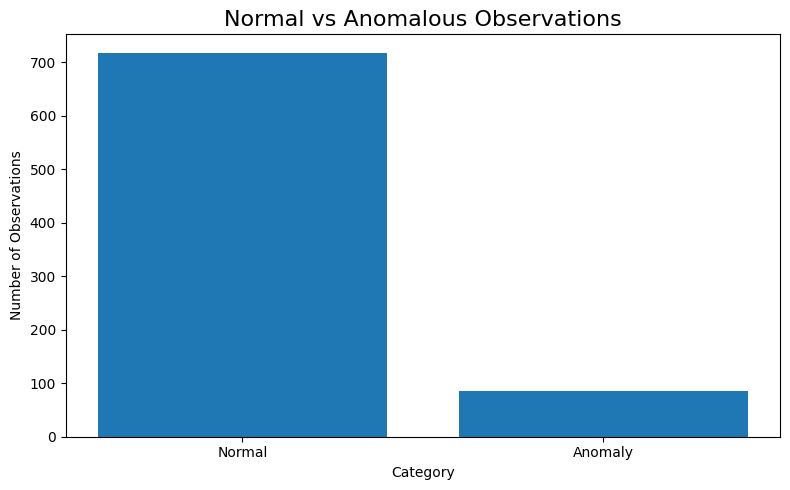

In [114]:
plt.figure(figsize=(8, 5))

plt.bar(
    ["Normal", "Anomaly"],
    [normal_count, anomaly_count]
)

plt.title(
    "Normal vs Anomalous Observations",
    fontsize=16
)

plt.xlabel("Category")
plt.ylabel("Number of Observations")

plt.tight_layout()
plt.show()

In [118]:
print("\nDataset")
print("Total Records:", len(df))

print("\nTraining")
print("Training Records:", len(train_data))

print("\nTesting")
print("Testing Records:", len(test_data))

print("\nZ-Score Baseline")
print("Z-Score Anomalies:", z_test_count)

print("\nIsolation Forest")
print("Isolation Forest Anomalies:", iforest_test_count)

print(
    "Isolation Forest Anomaly Percentage:",
    round(
        iforest_test_count /
        len(test_data) * 100,
        2
    ),
    "%"
)

print(
    "Selected Contamination:",
    contamination_value
)





Dataset
Total Records: 4032

Training
Training Records: 3206

Testing
Testing Records: 802

Z-Score Baseline
Z-Score Anomalies: 0

Isolation Forest
Isolation Forest Anomalies: 86
Isolation Forest Anomaly Percentage: 10.72 %
Selected Contamination: 0.02


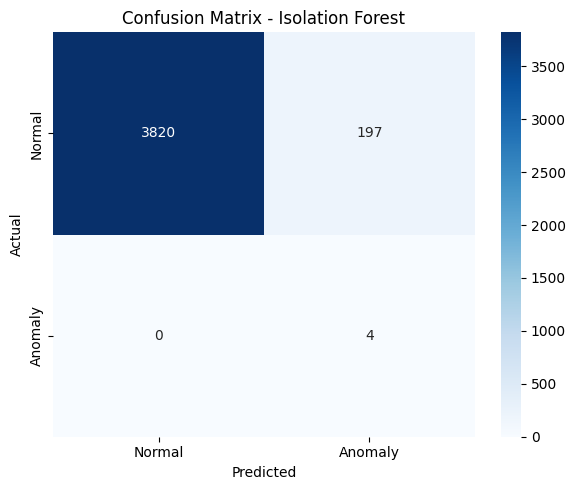

In [119]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Anomaly"],
    yticklabels=["Normal", "Anomaly"]
)

plt.title("Confusion Matrix - Isolation Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()